# 02 · 01 with 500 train / 50 val images per class


In [1]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch

# torch.set_num_threads(8)
# print("PyTorch CPU threads:", torch.get_num_threads())

from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from src.dataset.balanced_class_subset import BalancedClassSubset
from src.dataset.tiny_imagenet_dataset import TinyImageNetLoader, get_tiny_imagenet_class_names
from archive.utils import means, stds, convert_to_rgb, show_image, get_device, print_device_info
from archive.utils import apply_mixup, apply_cutmix

RESUME = False
SEED = 42
NUM_CLASSES = 200
TRAIN_PER_CLASS = 500
VAL_PER_CLASS = 50
BATCH_SIZE = 64
NUM_WORKERS = 4
EPOCHS = 100
INITIAL_LR = 0.05
MIN_LR = 1e-05
WEIGHT_DECAY = 0.0001
LABEL_SMOOTHING = 0.1
CLASSIFIER_DROPOUT = 0.20
CLEAN_EVAL_INTERVAL = 5

MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0
CLEAN_PROB = 0.25
MIXUP_PROB = 0.375
CUTMIX_PROB = 0.375

assert abs(CLEAN_PROB + MIXUP_PROB + CUTMIX_PROB - 1.0) < 1e-12

SAVE_DIR = Path('checkpoints_02_rand3_7')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = get_device()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Device:', DEVICE)
print('DataLoader workers:', NUM_WORKERS)
print('Epochs:', EPOCHS)
print(f'Batch probabilities: Clean={CLEAN_PROB:.0%} | MixUp={MIXUP_PROB:.0%} | CutMix={CUTMIX_PROB:.0%}')
print(f'MixUp alpha={MIXUP_ALPHA} | CutMix alpha={CUTMIX_ALPHA}')

Device: mps
DataLoader workers: 4
Epochs: 100
Batch probabilities: Clean=25% | MixUp=38% | CutMix=38%
MixUp alpha=0.2 | CutMix alpha=1.0


In [2]:
print_device_info(DEVICE)

Number of MPS devices: 1


## 1. Local model and reference dataset loader

In [3]:
TINY_ROOT = Path('../../../data/tiny_imagenet/tiny-imagenet-200')
SELECTED_CLASSES = list(range(NUM_CLASSES))
print('Dataset root:', TINY_ROOT)

Dataset root: ../../data/tiny_imagenet/tiny-imagenet-200


In [4]:
train_tf = transforms.Compose([transforms.Lambda(convert_to_rgb), transforms.RandomCrop(64, padding=4, padding_mode='reflect'), transforms.RandomHorizontalFlip(p=0.5), transforms.RandAugment(num_ops=3, magnitude=7), transforms.ToTensor(), transforms.Normalize(mean=means, std=stds)])
test_tf = transforms.Compose([transforms.Lambda(convert_to_rgb), transforms.ToTensor(), transforms.Normalize(mean=means, std=stds)])

train_dataset, val_dataset, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=train_tf, test_transform=test_tf).load()
clean_train_dataset, _, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=test_tf, test_transform=test_tf).load()

if not hasattr(clean_train_dataset, 'transform'):
    raise AttributeError('Expected the dataset to expose a transform attribute.')

train_subset = BalancedClassSubset(train_dataset, SELECTED_CLASSES, TRAIN_PER_CLASS, seed=SEED)
clean_train_subset = BalancedClassSubset(clean_train_dataset, SELECTED_CLASSES, TRAIN_PER_CLASS, seed=SEED)
val_subset = BalancedClassSubset(val_dataset, SELECTED_CLASSES, VAL_PER_CLASS, seed=SEED + 1)

assert train_subset.samples == clean_train_subset.samples, 'Clean and augmented training subsets differ.'
assert len(train_subset) == NUM_CLASSES * TRAIN_PER_CLASS
assert len(val_subset) == NUM_CLASSES * VAL_PER_CLASS

FULL_CLASS_NAMES = get_tiny_imagenet_class_names(train_dataset, TINY_ROOT)
CLASS_NAMES = [FULL_CLASS_NAMES[i] for i in SELECTED_CLASSES]

print('Train:', len(train_subset), 'Validation:', len(val_subset))

Train: 100000 Validation: 10000


## 2. DataLoaders (macOS / Jupyter safe)

In [5]:
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader_options = {'batch_size': BATCH_SIZE, 'num_workers': NUM_WORKERS, 'pin_memory': DEVICE.type == 'cuda', 'persistent_workers': NUM_WORKERS > 0, **({'prefetch_factor': 2} if NUM_WORKERS > 0 else {})}

train_loader = DataLoader(train_subset, shuffle=True, generator=loader_generator, **loader_options)
val_loader = DataLoader(val_subset, shuffle=False, **loader_options)
clean_train_loader = DataLoader(clean_train_subset, shuffle=False, **loader_options)

print('Training batches:', len(train_loader))
print('Validation batches:', len(val_loader))

Training batches: 1563
Validation batches: 157


## Visual Check

In [ ]:
# NUM_SHOW = 5
#
# train_iter = iter(train_loader)
# clean_train_iter = iter(clean_train_loader)
# val_iter = iter(val_loader)

In [ ]:
# train_images, train_labels = next(train_iter)
# clean_train_images, clean_train_labels = next(clean_train_iter)
# val_images, val_labels_batch = next(val_iter)
#
# show_image(train_images, train_labels, NUM_SHOW, CLASS_NAMES, name="Train Images", has_norm=True)
# show_image(clean_train_images, clean_train_labels, NUM_SHOW, CLASS_NAMES, name="Clean Train Images", has_norm=True)
# show_image(val_images, val_labels_batch, NUM_SHOW, CLASS_NAMES, name="Validation Images", has_norm=True)

In [ ]:
# mixup_images, mixup_labels_a, mixup_labels_b, mixup_lam, _ = apply_mixup(train_images.clone(), train_labels.clone(), alpha=MIXUP_ALPHA)
# cutmix_images, cutmix_labels_a, cutmix_labels_b, cutmix_lam, _ = apply_cutmix(train_images.clone(), train_labels.clone(), alpha=CUTMIX_ALPHA)
#
# show_mixed_images(mixup_images, mixup_labels_a, mixup_labels_b, mixup_lam, CLASS_NAMES, NUM_SHOW, name="MixUp Images", has_norm=True)
# show_mixed_images(cutmix_images, cutmix_labels_a, cutmix_labels_b, cutmix_lam, CLASS_NAMES, NUM_SHOW, name="CutMix Images", has_norm=True)

## 3. Model, optimizer and cosine scheduler

In [6]:
from archive._01_z_cnn._04_cnn_double_gap_2level_with_3layer_parameter.model import StandardCNN

base_model = StandardCNN(num_classes=NUM_CLASSES, block3_dropout=0.05, block4_dropout=0.10, classifier_dropout=CLASSIFIER_DROPOUT)
print('Parameters:', sum(p.numel() for p in base_model.parameters()))
print('Architecture: 10Conv (2+2+3+3) | No final MaxPool | GAP -> 512 -> 512 -> 200')
assert sum(isinstance(m, nn.Conv2d) for m in base_model.modules()) == 10
assert not any(isinstance(m, nn.MaxPool2d) for m in base_model.level4.modules())

model = base_model.to(DEVICE)

def raw_model():
    return model

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.SGD(model.parameters(), lr=INITIAL_LR, momentum=0.9, weight_decay=WEIGHT_DECAY, nesterov=True)

TOTAL_STEPS = EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TOTAL_STEPS, eta_min=MIN_LR)

Parameters: 8003720
Architecture: 10Conv (2+2+3+3) | No final MaxPool | GAP -> 512 -> 512 -> 200


## 4. Best and latest checkpoints

`best_model.pth` stores the best validation model. `latest_checkpoint.pth` stores the last completed epoch, optimizer, scheduler, history, and RNG state.

For a fresh 25/37.5/37.5 experiment keep `RESUME=False`. If training is interrupted, set `RESUME=True` and rerun the notebook to continue this same 100-epoch experiment.

In [7]:
BEST_PATH = SAVE_DIR / 'best_model.pth'
LATEST_PATH = SAVE_DIR / 'latest_checkpoint.pth'

history = {k: [] for k in ['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'clean_train_loss', 'clean_train_acc', 'lr', 'generalization_gap']}

best_acc = -1.0
best_epoch = 0
start_epoch = 1

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None, loader=loader_generator.get_state())

def restore_rng(s):
    random.setstate(s['python'])
    np.random.set_state(s['numpy'])
    torch.set_rng_state(s['torch'])
    if torch.cuda.is_available() and s.get('cuda') is not None:
        torch.cuda.set_rng_state_all(s['cuda'])
    loader_generator.set_state(s['loader'])

def save_latest(epoch):
    payload = dict(epoch=epoch, model=raw_model().state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(), history=history, best_acc=best_acc, best_epoch=best_epoch, rng=rng_state(), config=dict(num_classes=NUM_CLASSES, batch_size=BATCH_SIZE, epochs=EPOCHS, train_per_class=TRAIN_PER_CLASS, val_per_class=VAL_PER_CLASS, classifier='10conv_no_final_pool_dense_fc', classifier_dropout=CLASSIFIER_DROPOUT, augmentation='randaugment_3_7_25clean_375mixup_375cutmix', mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA, clean_prob=CLEAN_PROB, mixup_prob=MIXUP_PROB, cutmix_prob=CUTMIX_PROB))
    temp = LATEST_PATH.with_suffix('.tmp')
    torch.save(payload, temp)
    os.replace(temp, LATEST_PATH)

if RESUME:
    ck = torch.load(LATEST_PATH, map_location='cpu', weights_only=False)
    cfg = ck['config']

    if cfg['batch_size'] != BATCH_SIZE or cfg['epochs'] != EPOCHS or cfg.get('classifier') != '10conv_no_final_pool_dense_fc' or cfg.get('classifier_dropout') != CLASSIFIER_DROPOUT or cfg.get('augmentation') != 'randaugment_3_7_25clean_375mixup_375cutmix' or cfg.get('mixup_alpha') != MIXUP_ALPHA or cfg.get('cutmix_alpha') != CUTMIX_ALPHA or cfg.get('clean_prob') != CLEAN_PROB or cfg.get('mixup_prob') != MIXUP_PROB or cfg.get('cutmix_prob') != CUTMIX_PROB:
        raise ValueError('Resume configuration does not match this GAP + 25% Clean + 37.5% MixUp + 37.5% CutMix experiment.')

    raw_model().load_state_dict(ck['model'])
    optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler'])

    for state in optimizer.state.values():
        for k, v in state.items():
            if torch.is_tensor(v):
                state[k] = v.to(DEVICE)

    history = ck['history']
    best_acc = ck['best_acc']
    best_epoch = ck['best_epoch']
    start_epoch = ck['epoch'] + 1
    restore_rng(ck['rng'])

    print(f'Resuming from epoch {start_epoch} | LR = {scheduler.get_last_lr()[0]:.10f}')
else:
    print('Starting fresh 10Conv + No Final Pool + Dense + 25% Clean + 37.5% MixUp + 37.5% CutMix training from epoch 1.')

Starting fresh 10Conv + No Final Pool + Dense + 25% Clean + 37.5% MixUp + 37.5% CutMix training from epoch 1.


## 5. 25% Clean + 37.5% MixUp + 37.5% CutMix training and validation

Each training batch uses exactly one path:

- 25% probability → normal augmented training batch, without MixUp/CutMix
- 37.5% probability → MixUp (`alpha=0.2`)
- 37.5% probability → CutMix (`alpha=1.0`)

Validation and periodic clean-train evaluation remain completely unmixed.

The experiment runs the full **100 epochs**. There is no LR-threshold stop and no validation early stopping.

In [8]:
def choose_batch_augmentation(images, labels):
    r = np.random.random()
    if r < CLEAN_PROB:
        return images, labels, labels, 1.0, 'Clean'
    if r < CLEAN_PROB + MIXUP_PROB:
        return apply_mixup(images, labels, alpha=MIXUP_ALPHA)
    return apply_cutmix(images, labels, alpha=CUTMIX_ALPHA)

def run_epoch(loader, training=False):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = torch.zeros((), device=DEVICE)
    total_correct = torch.zeros((), device=DEVICE)
    total = 0
    clean_batches = 0
    mixup_batches = 0
    cutmix_batches = 0
    context = torch.enable_grad() if training else torch.inference_mode()

    with context:
        for images, labels in tqdm(loader, leave=False, desc='Train' if training else 'Eval'):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)
                model_images, labels_a, labels_b, lam, batch_type = choose_batch_augmentation(images, labels)

                if batch_type == 'Clean':
                    clean_batches += 1
                elif batch_type == 'MixUp':
                    mixup_batches += 1
                else:
                    cutmix_batches += 1

                logits = model(model_images)

                if batch_type == 'Clean':
                    loss = criterion(logits, labels)
                    correct = (logits.detach().argmax(dim=1) == labels).sum()
                else:
                    loss = lam * criterion(logits, labels_a) + (1.0 - lam) * criterion(logits, labels_b)
                    predictions = logits.detach().argmax(dim=1)
                    correct = lam * (predictions == labels_a).sum() + (1.0 - lam) * (predictions == labels_b).sum()

                loss.backward()
                optimizer.step()
                scheduler.step()
            else:
                logits = model(images)
                loss = criterion(logits, labels)
                correct = (logits.detach().argmax(dim=1) == labels).sum()

            batch_size = labels.size(0)
            total += batch_size
            total_loss += loss.detach() * batch_size
            total_correct += correct

    avg_loss = (total_loss / total).item()
    accuracy = (total_correct * (100.0 / total)).item()

    if training:
        print(f'Batch selection: Clean={clean_batches}, MixUp={mixup_batches}, CutMix={cutmix_batches}')

    return avg_loss, accuracy

In [9]:
for epoch in tqdm(range(start_epoch, EPOCHS + 1)):
    train_loss, train_acc = run_epoch(train_loader, training=True)

    if epoch == 1 or epoch % CLEAN_EVAL_INTERVAL == 0:
        clean_train_loss, clean_train_acc = run_epoch(clean_train_loader, training=False)
    else:
        clean_train_loss, clean_train_acc = None, None

    val_loss, val_acc = run_epoch(val_loader, training=False)
    current_lr = optimizer.param_groups[0]['lr']

    epoch_metrics = {'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc, 'val_loss': val_loss, 'val_acc': val_acc, 'clean_train_loss': clean_train_loss, 'clean_train_acc': clean_train_acc, 'lr': current_lr, 'generalization_gap': clean_train_acc - val_acc if clean_train_acc is not None else None}

    for name, value in epoch_metrics.items():
        history[name].append(value)

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch
        torch.save({'model': raw_model().state_dict(), 'epoch': epoch, 'val_acc': val_acc, 'class_names': CLASS_NAMES, 'experiment': '10Conv ReLU + No Final Pool + Dense + 25% Clean + 37.5% MixUp + 37.5% CutMix'}, BEST_PATH)

    save_latest(epoch)

    clean_text = f'{clean_train_acc:.2f}% / {clean_train_loss:.4f}' if clean_train_acc is not None else 'Skipped'
    print(f'Epoch {epoch:03d}/{EPOCHS} | Train: {train_acc:.2f}% / {train_loss:.4f} | Val: {val_acc:.2f}% / {val_loss:.4f} | Clean Train: {clean_text} | LR: {current_lr:.7f} | Best: {best_acc:.2f}% (epoch {best_epoch})')

print(f'Training finished at epoch {EPOCHS}. Best validation accuracy: {best_acc:.2f}% (epoch {best_epoch})')

  0%|          | 0/100 [00:00<?, ?it/s]

Train:   0%|          | 0/1563 [00:06<?, ?it/s]

Batch selection: Clean=410, MixUp=576, CutMix=577


Eval:   0%|          | 0/1563 [00:06<?, ?it/s]

Eval:   0%|          | 0/157 [00:04<?, ?it/s]

Epoch 001/100 | Train: 2.89% / 5.0451 | Val: 6.47% / 4.6148 | Clean Train: 6.70% / 4.6192 | LR: 0.0499877 | Best: 6.47% (epoch 1)


... (412 outputs left out)

Batch selection: Clean=415, MixUp=569, CutMix=579


Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 100/100 | Train: 70.31% / 2.2266 | Val: 66.60% / 2.0944 | Clean Train: 97.22% / 1.0838 | LR: 0.0000100 | Best: 66.60% (epoch 100)
Training finished at epoch 100. Best validation accuracy: 66.60% (epoch 100)


## 6. Training and validation curves

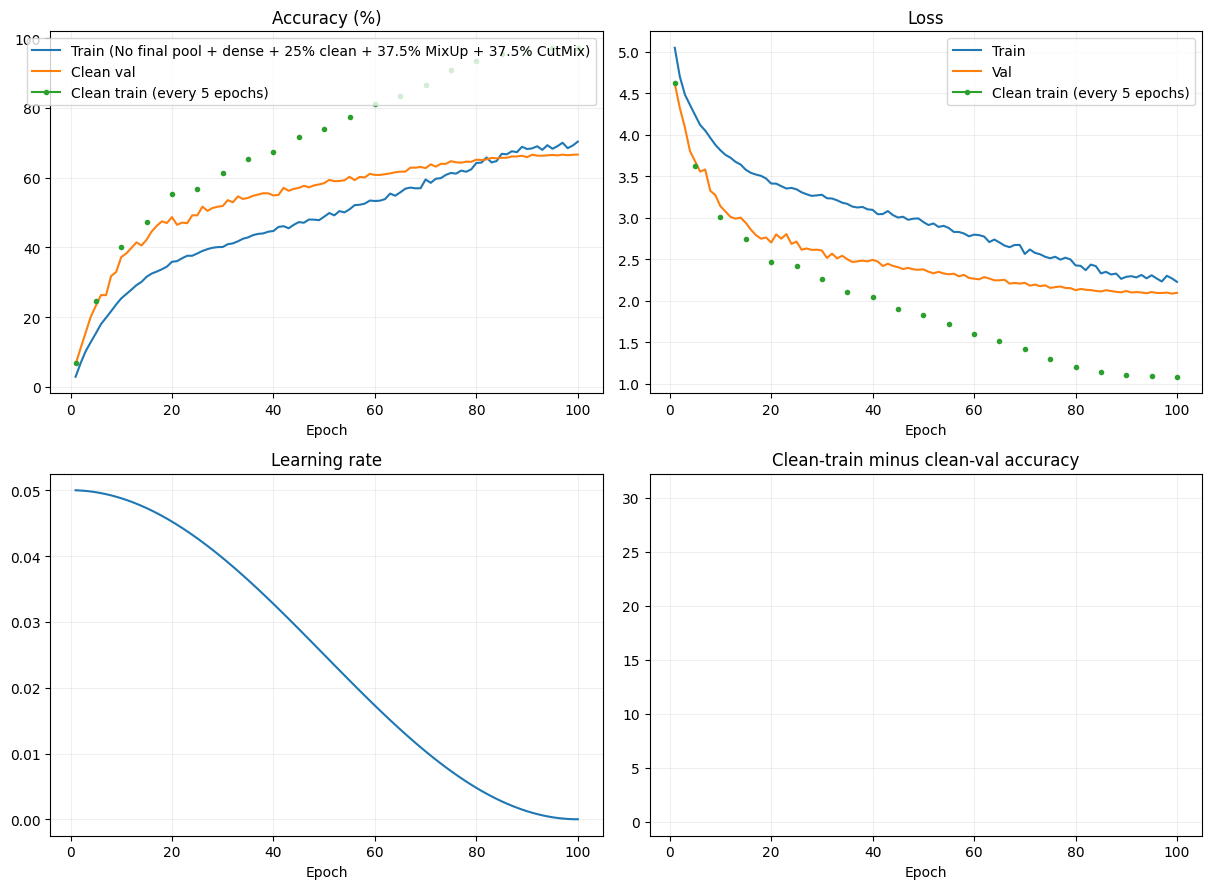

Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/157 [00:00<?, ?it/s]

Best checkpoint: clean train 97.22%, clean val 66.60%, gap 30.62 pp


In [10]:
h = pd.DataFrame(history)
fig, axs = plt.subplots(2, 2, figsize=(13, 9))

axs[0, 0].plot(h.epoch, h.train_acc, label='Train (No final pool + dense + 25% clean + 37.5% MixUp + 37.5% CutMix)')
axs[0, 0].plot(h.epoch, h.val_acc, label='Clean val')
axs[0, 0].plot(h.epoch, h.clean_train_acc, label='Clean train (every 5 epochs)', marker='o', markersize=3)
axs[0, 0].set_title('Accuracy (%)')
axs[0, 0].legend()

axs[0, 1].plot(h.epoch, h.train_loss, label='Train')
axs[0, 1].plot(h.epoch, h.val_loss, label='Val')
axs[0, 1].plot(h.epoch, h.clean_train_loss, label='Clean train (every 5 epochs)', marker='o', markersize=3)
axs[0, 1].set_title('Loss')
axs[0, 1].legend()

axs[1, 0].plot(h.epoch, h.lr)
axs[1, 0].set_title('Learning rate')

axs[1, 1].plot(h.epoch, h.generalization_gap)
axs[1, 1].set_title('Clean-train minus clean-val accuracy')

for ax in axs.flat:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

best = torch.load(BEST_PATH, map_location='cpu', weights_only=False)
raw_model().load_state_dict(best['model'])
model.eval()

clean_train_loss, clean_train_acc = run_epoch(clean_train_loader)
clean_val_loss, clean_val_acc = run_epoch(val_loader)

print(f'Best checkpoint: clean train {clean_train_acc:.2f}%, clean val {clean_val_acc:.2f}%, gap {clean_train_acc - clean_val_acc:.2f} pp')

Device: mps
Checkpoint: checkpoints_10conv_relu_no_final_pool_dense_25clean_375mixup_375cutmix_2/best_model.pth
Best epoch: 100
Best validation accuracy: 66.5999984741211
Output directory: /Users/sumanneupane/Documents/MIT in AI/Semister 4/cnn_vs_pc_cnn/z_cnn/more_classifier/checkpoints_10conv_relu_no_final_pool_dense_25clean_375mixup_375cutmix_2/cnn_full_diagnostics
level1_conv1       | level1.2        | ReLU
level1_conv2       | level1.5        | ReLU
level2_conv1       | level2.2        | ReLU
level2_conv2       | level2.5        | ReLU
level3_conv1       | level3.2        | ReLU
level3_conv2       | level3.5        | ReLU
level3_conv3       | level3.8        | ReLU
level4_conv1       | level4.2        | ReLU
level4_conv2       | level4.5        | ReLU
level4_conv3       | level4.8        | ReLU
global_pool        | global_pool     | AdaptiveAvgPool2d
dense_transition   | dense_transition | Sequential
classifier         | classifier      | Linear


Analyzing all activations:   0%|          | 0/157 [00:00<?, ?it/s]


=== ACTIVATION SUMMARY: ALL 13 COMPONENTS ===


,level,output_shape,total_units,inactive_units,rare_units,inactive_pct,rare_pct,mean_active_units_per_image,mean_active_position_pct,mean_value,std_value,mean_abs_value,min_value,max_value
0,level1_conv1,"(64, 64, 64)",64,0,0,0.0,0.0,63.5073,59.4246,0.1708,0.2624,0.1708,0.0000,6.9961
1,level1_conv2,"(64, 64, 64)",64,0,0,0.0,0.0,63.9811,49.6098,0.1407,0.2239,0.1407,0.0000,6.3475
2,level2_conv1,"(128, 32, 32)",128,0,0,0.0,0.0,127.9299,47.7498,0.1288,0.2000,0.1288,0.0000,4.8444
3,level2_conv2,"(128, 32, 32)",128,0,0,0.0,0.0,127.9984,30.4830,0.0975,0.2172,0.0975,0.0000,5.7505
4,level3_conv1,"(256, 16, 16)",256,0,0,0.0,0.0,255.7531,31.9334,0.0838,0.1795,0.0838,0.0000,5.0431
5,level3_conv2,"(256, 16, 16)",256,0,0,0.0,0.0,255.8745,27.9712,0.0721,0.1663,0.0721,0.0000,6.3572
6,level3_conv3,"(256, 16, 16)",256,0,0,0.0,0.0,254.2340,14.1737,0.0362,0.1279,0.0362,0.0000,5.2832
7,level4_conv1,"(512, 8, 8)",512,0,0,0.0,0.0,490.5418,19.1315,0.0420,0.1244,0.0420,0.0000,5.7736
8,level4_conv2,"(512, 8, 8)",512,0,0,0.0,0.0,477.9478,14.1156,0.0291,0.1040,0.0291,0.0000,5.6462
9,level4_conv3,"(512, 8, 8)",512,0,0,0.0,0.0,356.5682,6.4626,0.0112,0.0624,0.0112,0.0000,4.4120


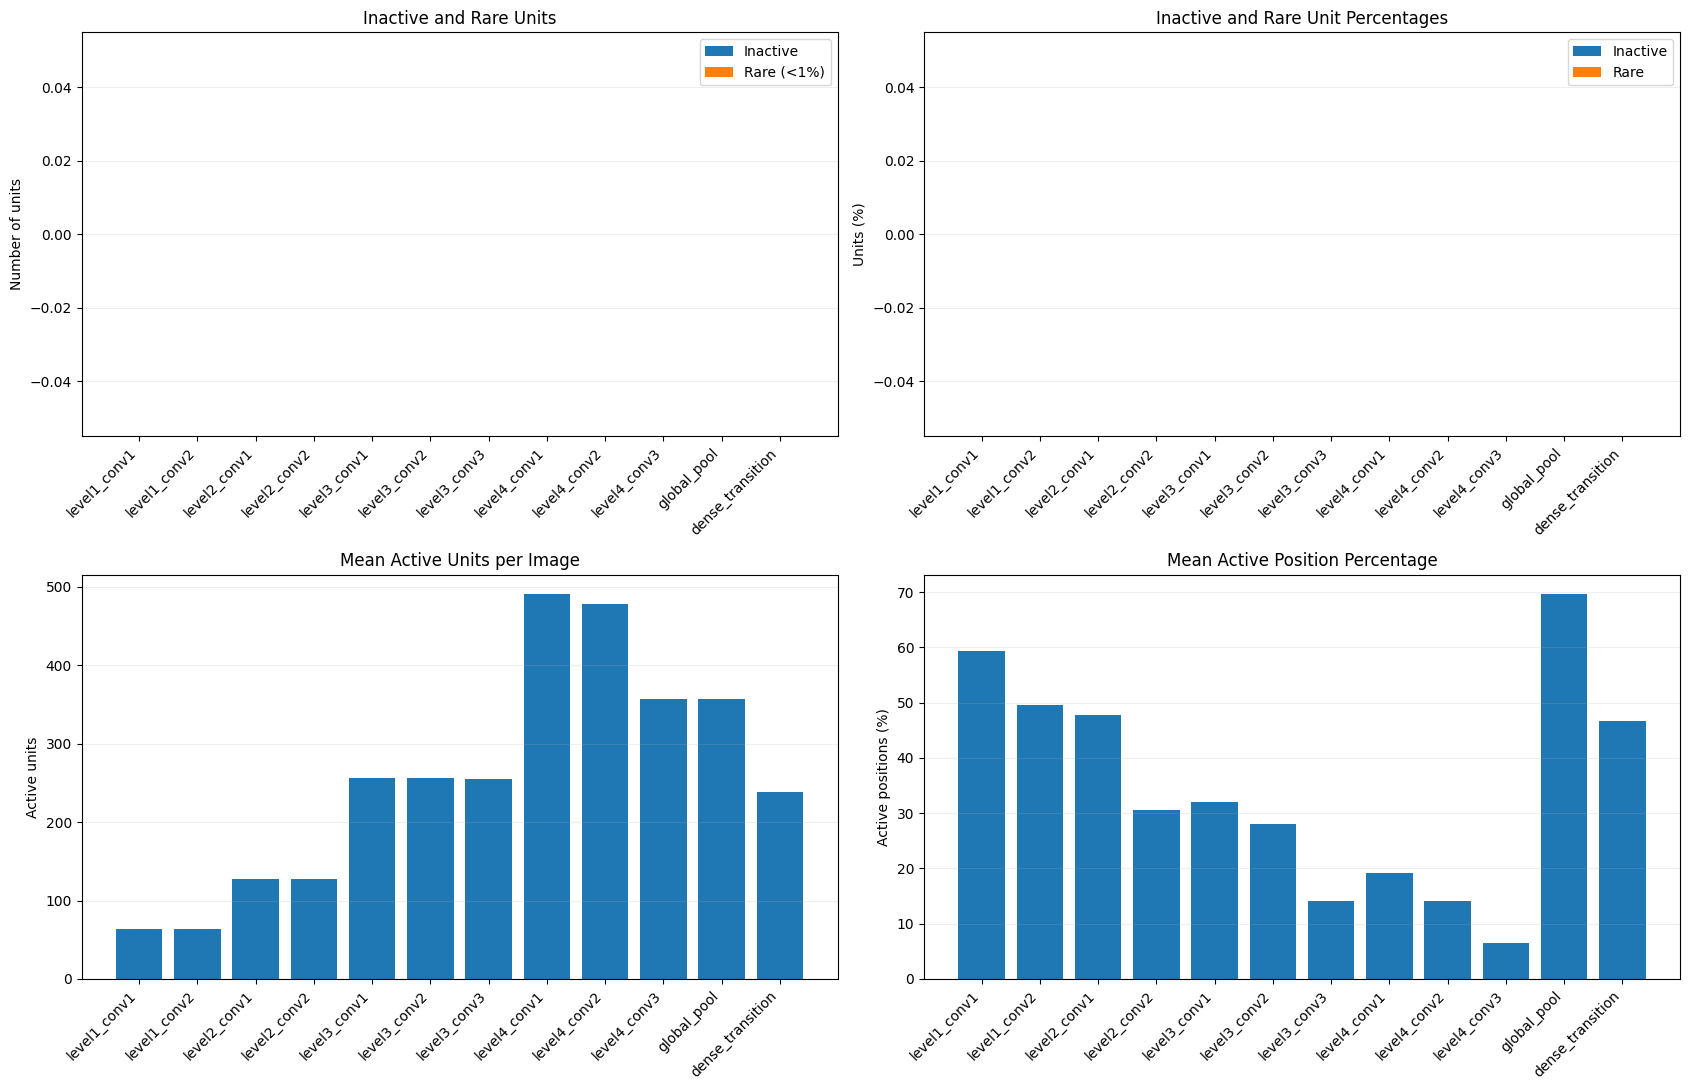

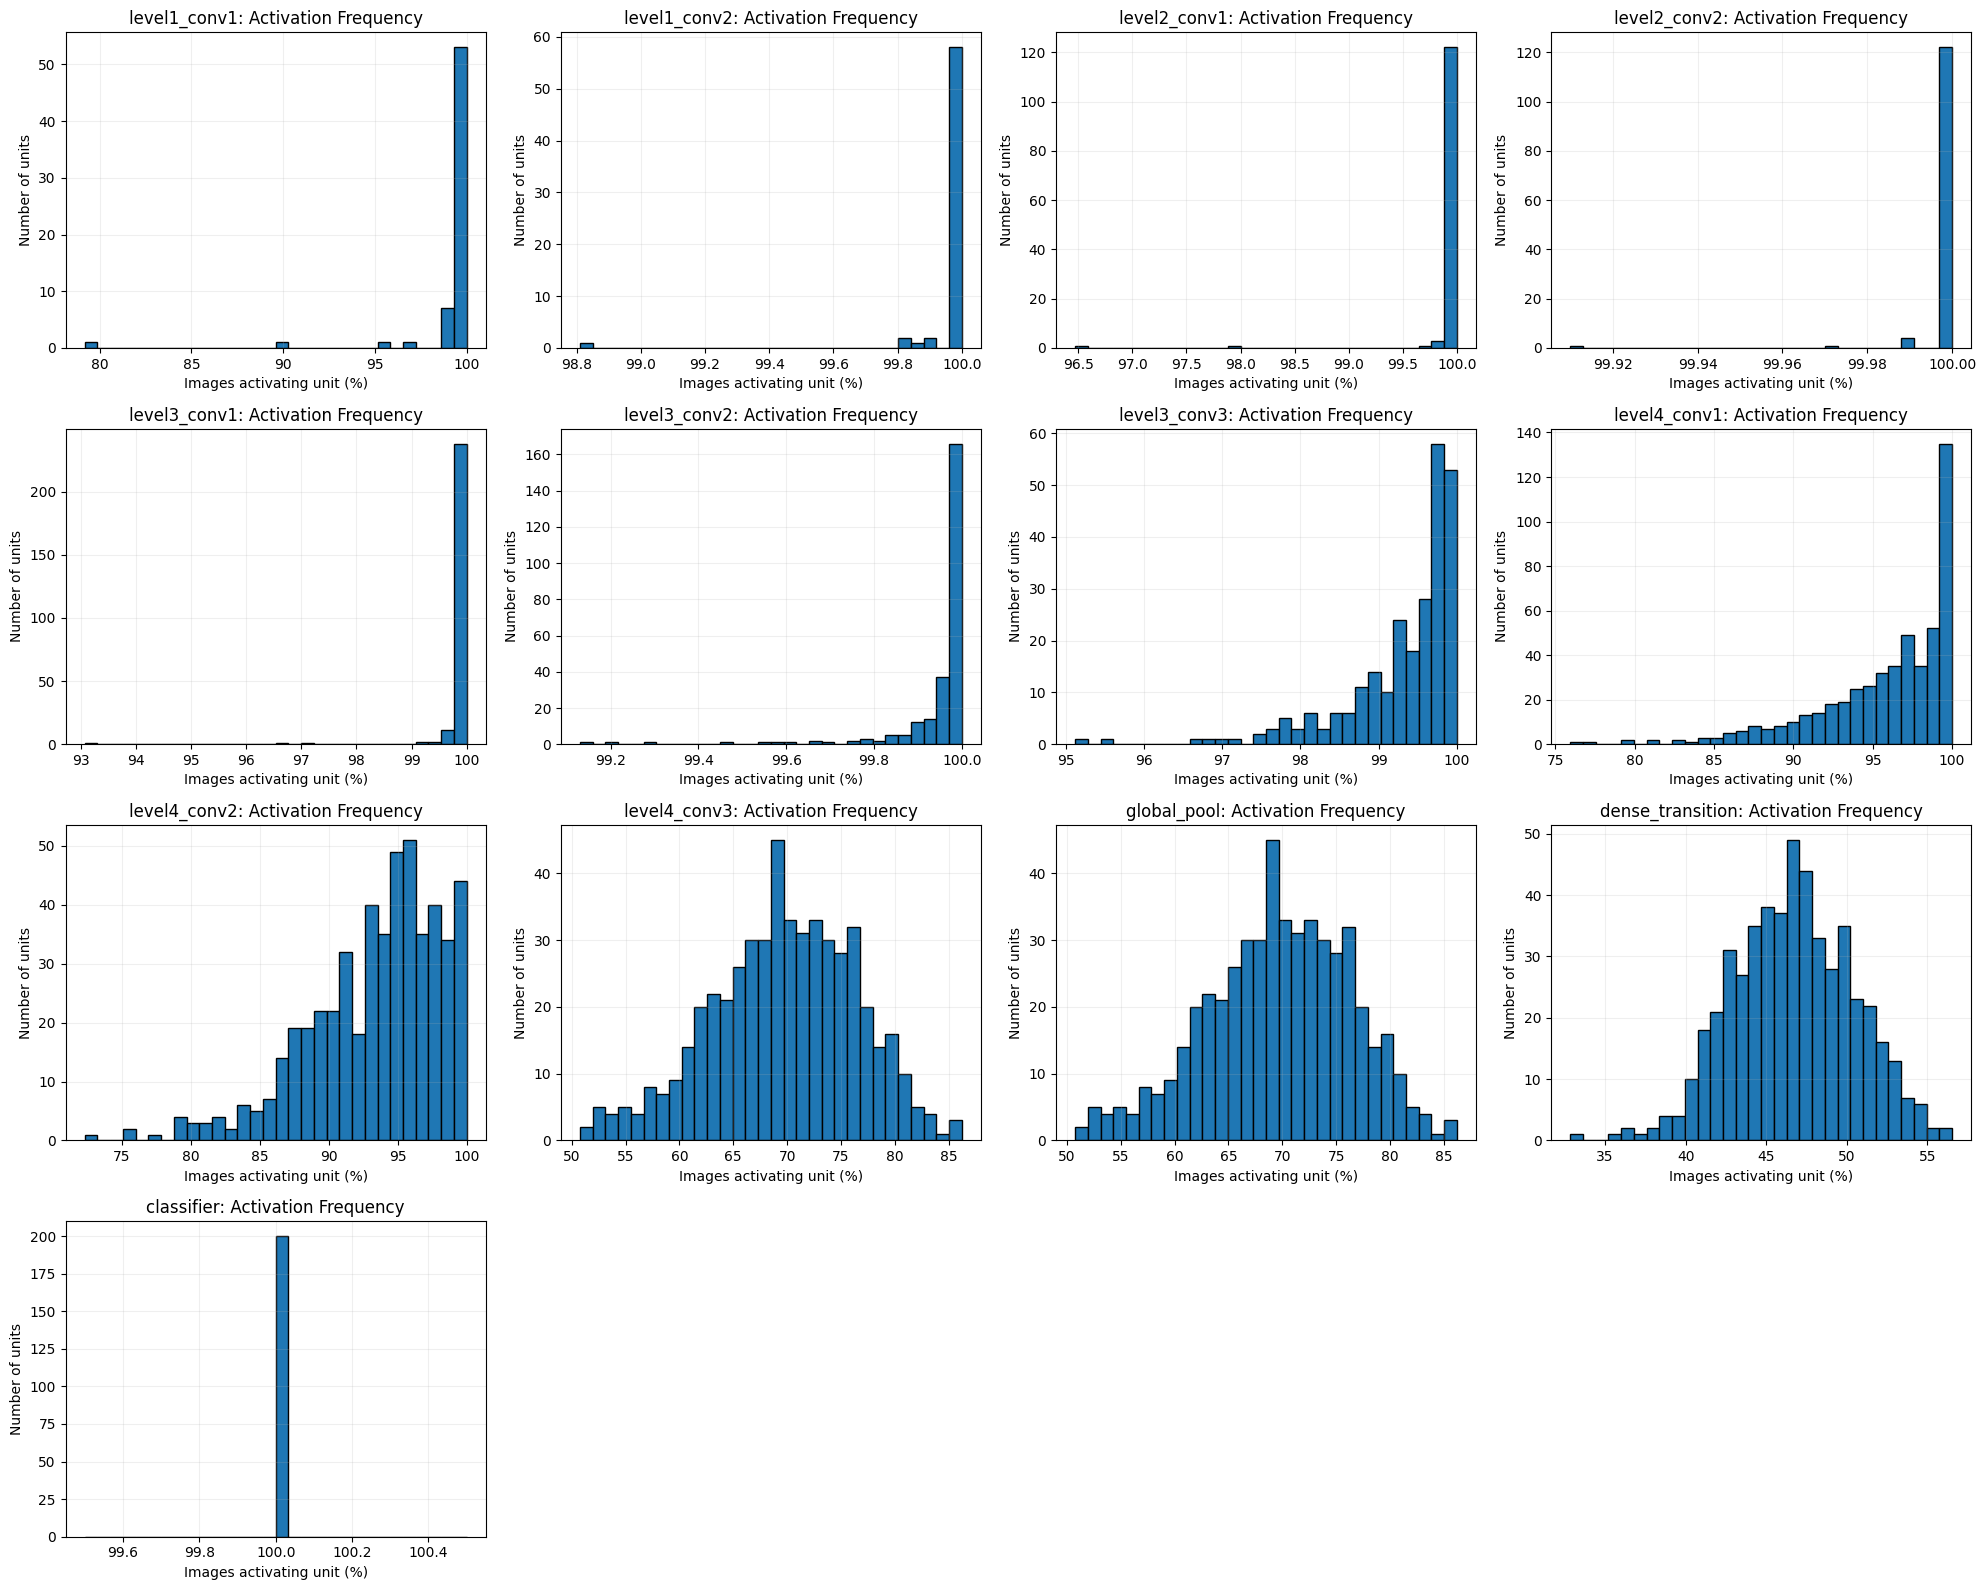

Analyzing gradients:   0%|          | 0/10 [00:00<?, ?it/s]


=== GRADIENT FLOW SUMMARY ===


,level,mean_gradient,median_gradient,min_gradient,max_gradient
3,level1_conv1,0.000032,0.000032,0.000016,0.000048
4,level1_conv2,0.000017,0.000017,0.000012,0.000026
5,level2_conv1,0.000046,0.000046,0.000030,0.000065
6,level2_conv2,0.000021,0.000021,0.000016,0.000030
7,level3_conv1,0.000083,0.000081,0.000064,0.000122
8,level3_conv2,0.000084,0.000083,0.000069,0.000133
9,level3_conv3,0.000051,0.000050,0.000046,0.000058
10,level4_conv1,0.000216,0.000214,0.000187,0.000293
11,level4_conv2,0.000213,0.000211,0.000181,0.000354
12,level4_conv3,0.000236,0.000232,0.000182,0.000330


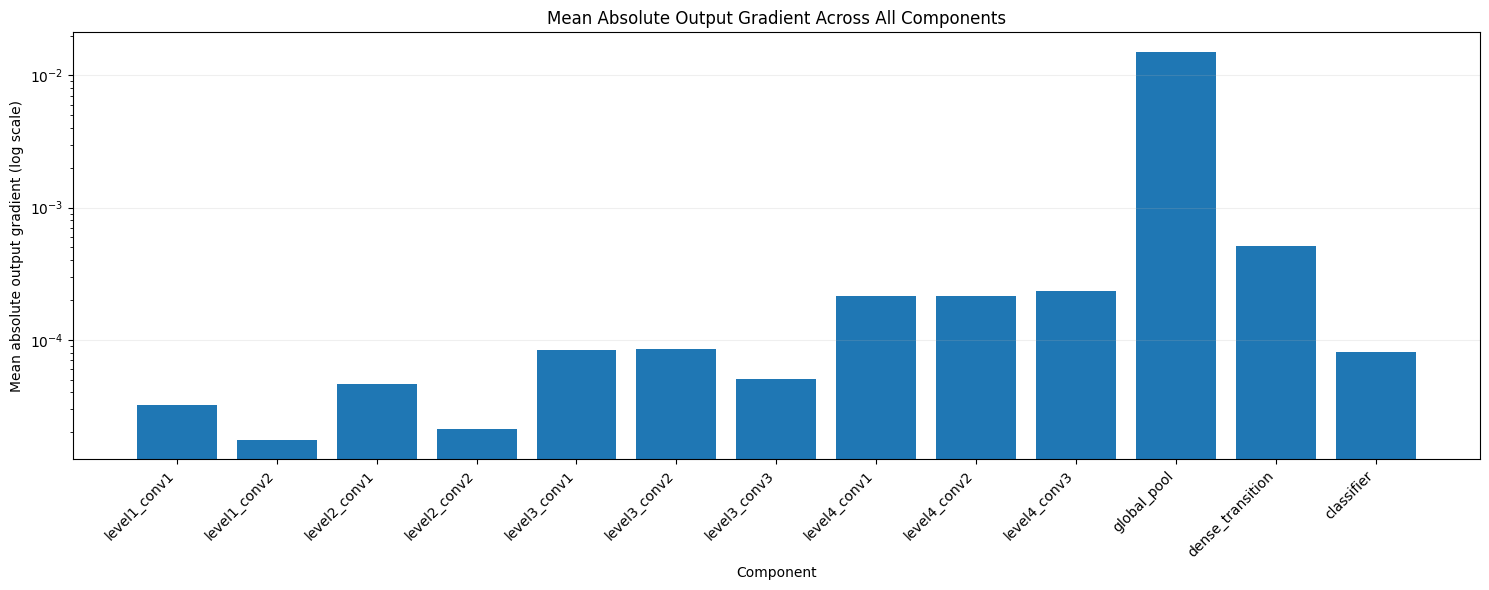


=== ACTIVATION VS GRADIENT COMPARISON ===


,level,total_units,inactive_units,rare_units,near_zero_gradient_units,inactive_and_low_gradient,rare_and_low_gradient
0,level1_conv1,64,0,0,0,0,0
1,level1_conv2,64,0,0,0,0,0
2,level2_conv1,128,0,0,0,0,0
3,level2_conv2,128,0,0,0,0,0
4,level3_conv1,256,0,0,0,0,0
5,level3_conv2,256,0,0,0,0,0
6,level3_conv3,256,0,0,0,0,0
7,level4_conv1,512,0,0,0,0,0
8,level4_conv2,512,0,0,0,0,0
9,level4_conv3,512,0,0,0,0,0


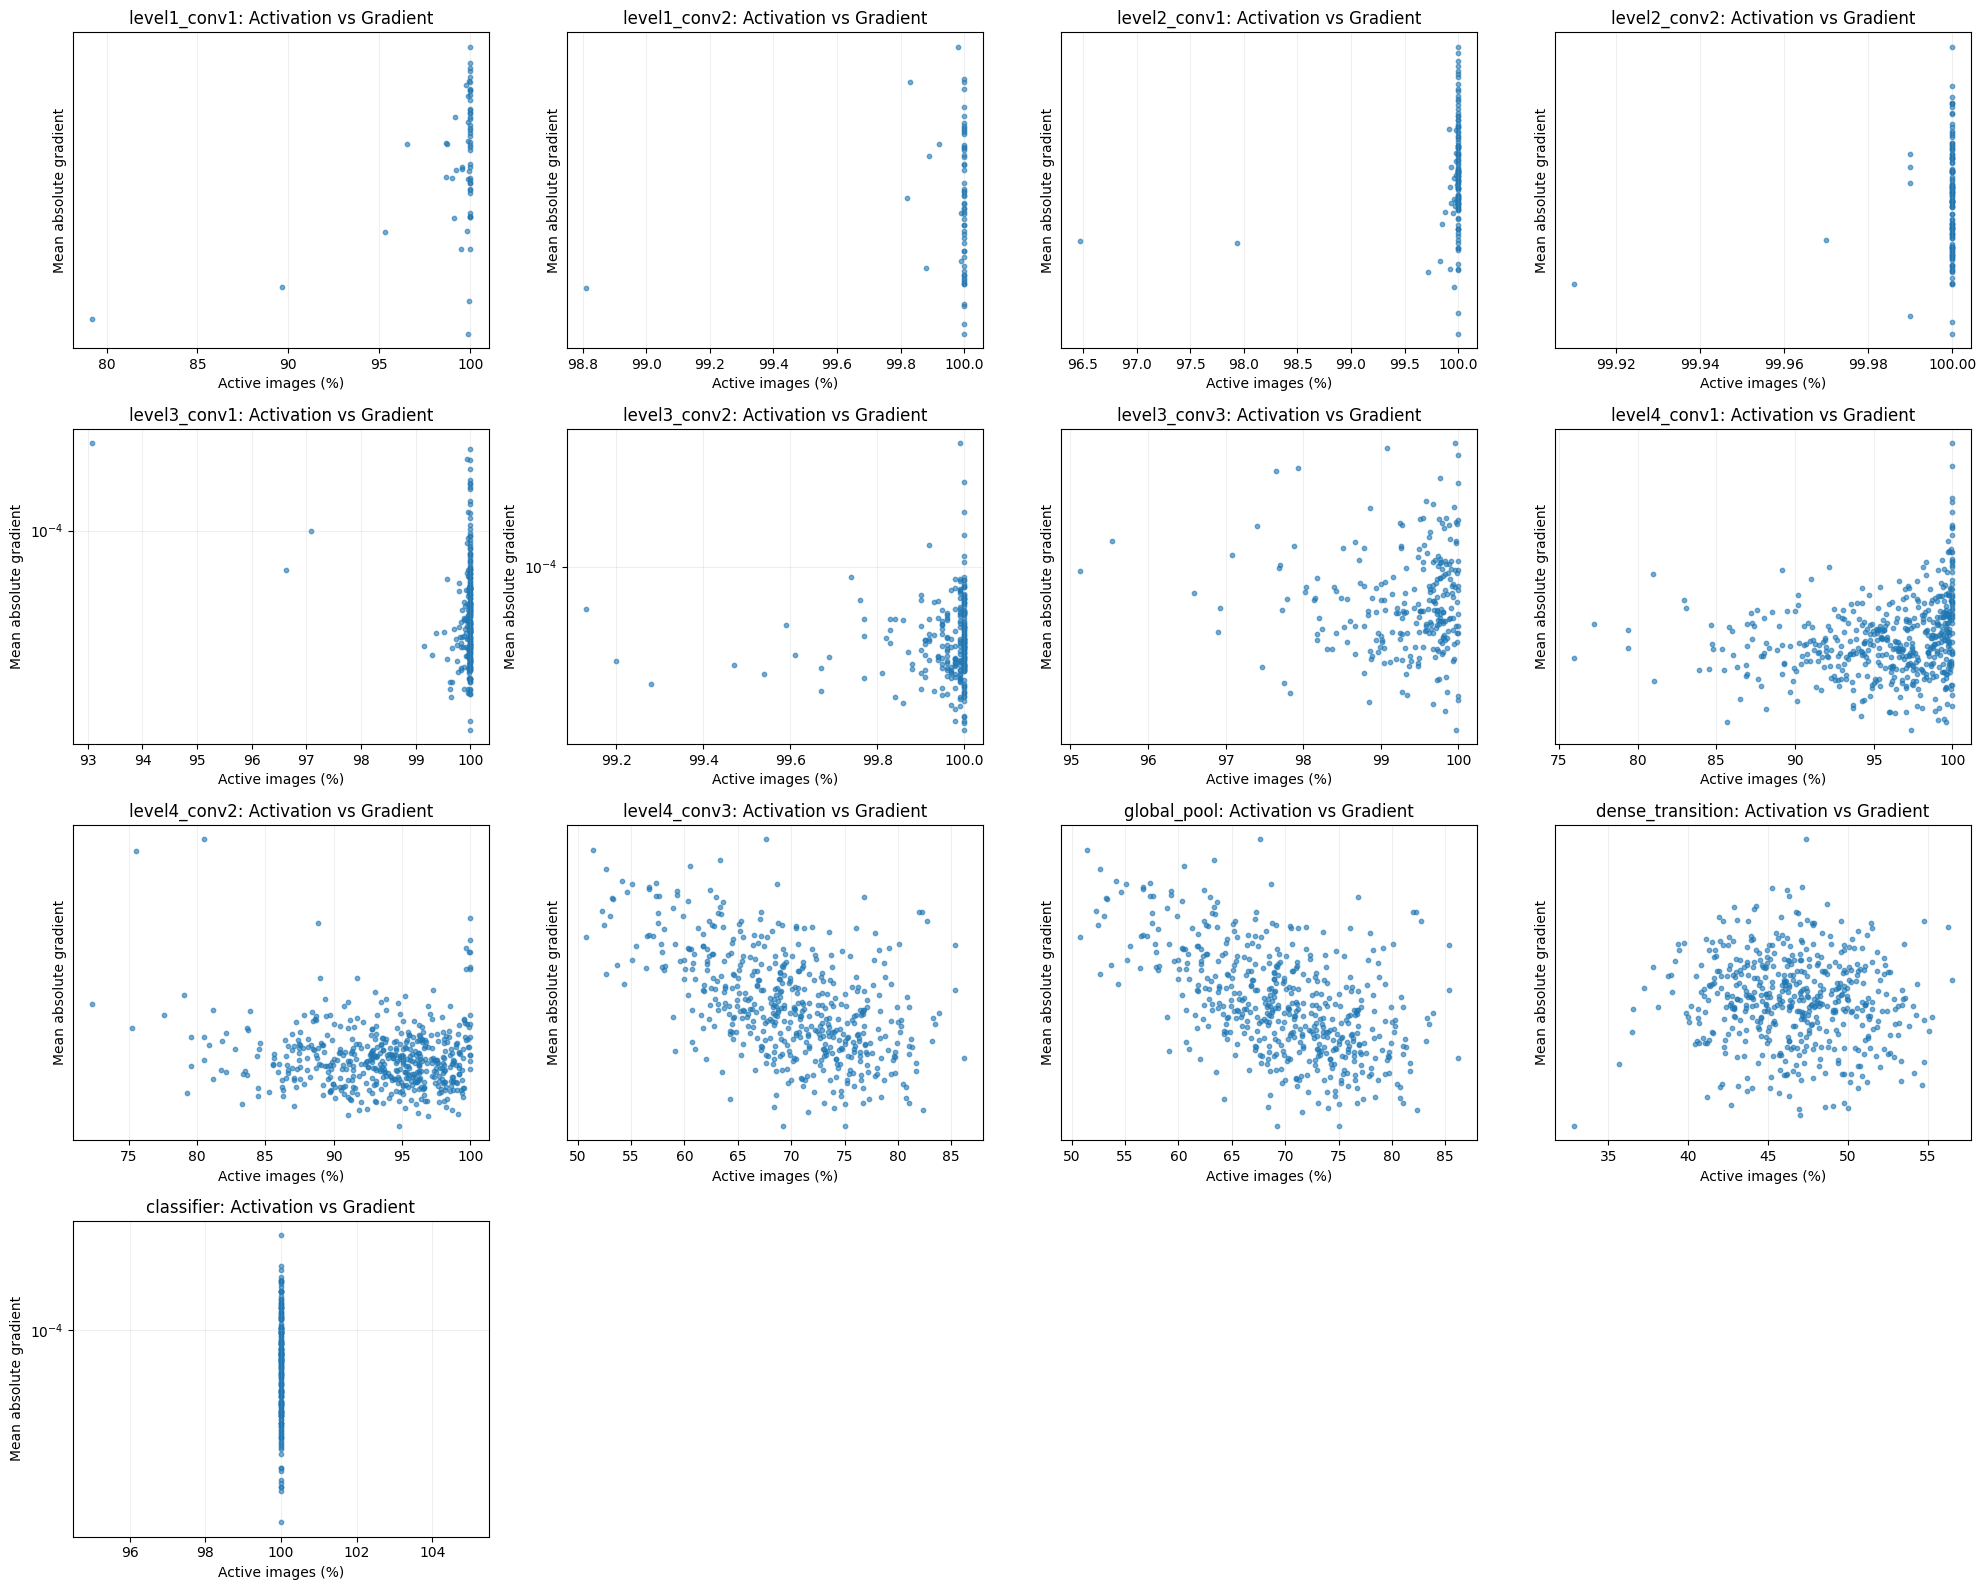

Analyzing classifier:   0%|          | 0/157 [00:00<?, ?it/s]


=== CLASSIFIER METRICS ===


,validation_accuracy_pct,mean_confidence_pct,mean_logit,std_logit,mean_abs_logit,predicted_classes_used,total_classes
0,66.6,55.1985,0.0004,1.0812,0.7582,200,200



=== CLASS-WISE CLASSIFIER RESULTS ===


,class_id,validation_images,predicted_images,correct_images,class_accuracy_pct
0,0,50,48,22,44.0
1,1,50,36,21,42.0
2,2,50,60,38,76.0
3,3,50,47,31,62.0
4,4,50,53,35,70.0
...,...,...,...,...,...
195,195,50,51,32,64.0
196,196,50,46,40,80.0
197,197,50,43,28,56.0
198,198,50,45,38,76.0


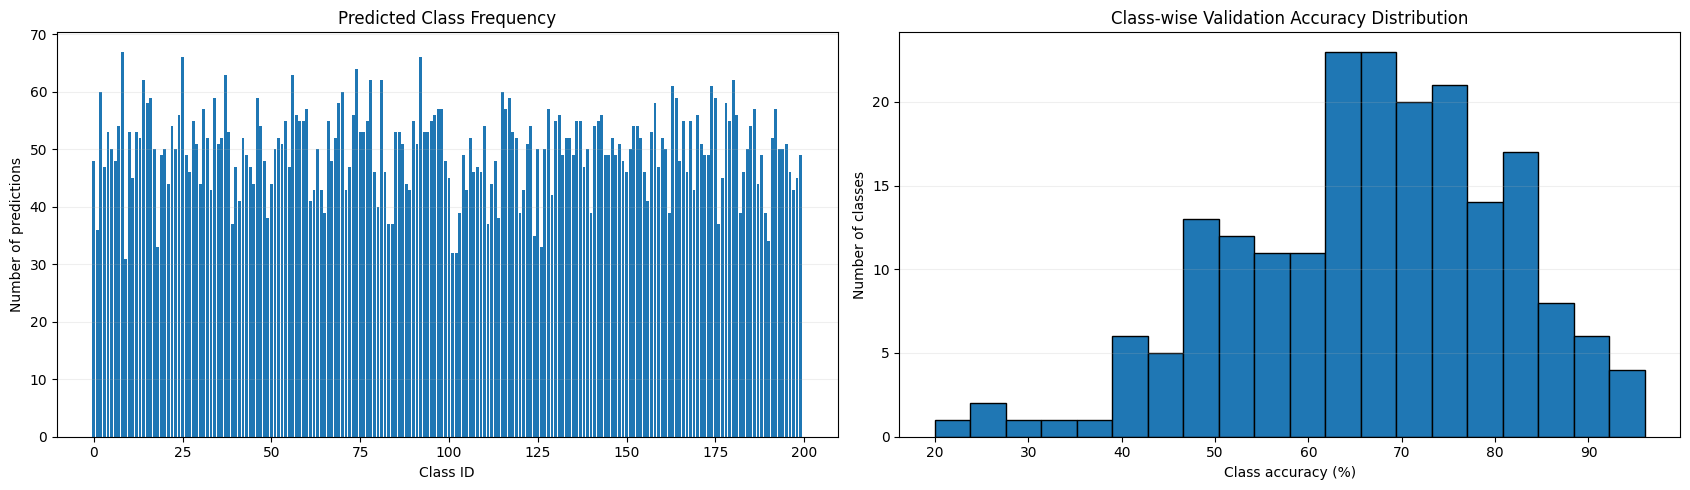


COMPLETE CNN DIAGNOSTIC REPORT: 10 CONV + POOL + FEATURES + CLASSIFIER

level1_conv1 (Channels/features)
  Total units             : 64
  Inactive units          : 0
  Rarely active units     : 0
  Near-zero gradients     : 0
  Inactive + low gradient : 0
  Rare + low gradient     : 0

level1_conv2 (Channels/features)
  Total units             : 64
  Inactive units          : 0
  Rarely active units     : 0
  Near-zero gradients     : 0
  Inactive + low gradient : 0
  Rare + low gradient     : 0

level2_conv1 (Channels/features)
  Total units             : 128
  Inactive units          : 0
  Rarely active units     : 0
  Near-zero gradients     : 0
  Inactive + low gradient : 0
  Rare + low gradient     : 0

level2_conv2 (Channels/features)
  Total units             : 128
  Inactive units          : 0
  Rarely active units     : 0
  Near-zero gradients     : 0
  Inactive + low gradient : 0
  Rare + low gradient     : 0

level3_conv1 (Channels/features)
  Total units             : 256


In [11]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 1. CONFIGURATION
# ============================================================

DEVICE = get_device()

BEST_PATH = SAVE_DIR / "best_model.pth"
OUTPUT_DIR = SAVE_DIR / "cnn_full_diagnostics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ACTIVATION_THRESHOLD = 1e-8
RARE_CHANNEL_THRESHOLD = 1.0
RELATIVE_GRADIENT_THRESHOLD = 1e-4
MAX_GRAD_BATCHES = 10

LAYER_NAMES = {
    "level1_conv1": "level1.2",
    "level1_conv2": "level1.5",
    "level2_conv1": "level2.2",
    "level2_conv2": "level2.5",
    "level3_conv1": "level3.2",
    "level3_conv2": "level3.5",
    "level3_conv3": "level3.8",
    "level4_conv1": "level4.2",
    "level4_conv2": "level4.5",
    "level4_conv3": "level4.8",
    "global_pool": "global_pool",
    "dense_transition": "dense_transition",
    "classifier": "classifier"
}

CONV_LAYERS = list(LAYER_NAMES)[:10]
POOL_LAYER = "global_pool"
FEATURE_LAYER = "dense_transition"
CLASSIFIER_LAYER = "classifier"

if not BEST_PATH.exists(): raise FileNotFoundError(f"Checkpoint not found: {BEST_PATH}")
if "val_loader" not in globals(): raise RuntimeError("val_loader not found.")
if "StandardCNN" not in globals(): raise RuntimeError("StandardCNN not found.")


# ============================================================
# 2. LOAD BEST MODEL
# ============================================================

checkpoint = torch.load(BEST_PATH, map_location="cpu", weights_only=False)

if isinstance(checkpoint, dict) and "model" in checkpoint:
    state_dict = checkpoint["model"]
elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

if not isinstance(state_dict, dict): raise TypeError("Could not find a valid model state_dict.")

if any(key.startswith("module.") for key in state_dict):
    state_dict = {key.removeprefix("module."): value for key, value in state_dict.items()}

model = StandardCNN(
    num_classes=NUM_CLASSES if "NUM_CLASSES" in globals() else 200,
    block3_dropout=0.05,
    block4_dropout=0.10,
    classifier_dropout=CLASSIFIER_DROPOUT if "CLASSIFIER_DROPOUT" in globals() else 0.30
)

model.load_state_dict(state_dict, strict=True)
model = model.to(DEVICE)
model.eval()

print("Device:", DEVICE)
print("Checkpoint:", BEST_PATH)
print("Best epoch:", checkpoint.get("epoch", "Unknown") if isinstance(checkpoint, dict) else "Unknown")
print("Best validation accuracy:", checkpoint.get("val_acc", "Unknown") if isinstance(checkpoint, dict) else "Unknown")
print("Output directory:", OUTPUT_DIR.resolve())


# ============================================================
# 3. VALIDATE ALL 13 COMPONENTS
# ============================================================

modules = dict(model.named_modules())

for level, name in LAYER_NAMES.items():
    if name not in modules: raise ValueError(f"{level}: Layer '{name}' not found.")
    if level in CONV_LAYERS and not isinstance(modules[name], nn.ReLU):
        raise TypeError(f"{name} must be a ReLU layer.")
    print(f"{level:18s} | {name:15s} | {type(modules[name]).__name__}")


# ============================================================
# 4. ACTIVATION ANALYSIS: 4D AND 2D OUTPUTS
# ============================================================

def analyze_activations(model, loader, device, layer_names, threshold=1e-8, rare_threshold=1.0):
    modules = dict(model.named_modules())
    stats = {}
    handles = []

    for level in layer_names:
        stats[level] = {
            "active_images": None,
            "active_positions": None,
            "total_images": 0,
            "total_positions": 0,
            "active_units_sum": 0.0,
            "active_spatial_sum": 0.0,
            "sum_values": 0.0,
            "sum_abs_values": 0.0,
            "sum_squared_values": 0.0,
            "num_values": 0,
            "min_value": float("inf"),
            "max_value": float("-inf"),
            "output_shape": None
        }

    def make_hook(level):
        def hook(module, inputs, output):
            x = output.detach()
            if x.ndim not in (2, 4): raise ValueError(f"{level}: Unsupported output shape {tuple(x.shape)}")

            b, c = x.shape[:2]
            s = stats[level]
            s["output_shape"] = tuple(x.shape[1:])

            if level == CLASSIFIER_LAYER:
                active = x.abs() > threshold
            else:
                active = x > threshold

            if x.ndim == 4:
                image_active = active.flatten(2).any(dim=2)
                position_counts = active.sum(dim=(0, 2, 3)).cpu().numpy()
                positions_per_image = x.shape[2] * x.shape[3]
            else:
                image_active = active
                position_counts = active.sum(dim=0).cpu().numpy()
                positions_per_image = 1

            image_counts = image_active.sum(dim=0).cpu().numpy()

            if s["active_images"] is None:
                s["active_images"] = np.zeros(c, dtype=np.int32)
                s["active_positions"] = np.zeros(c, dtype=np.int32)

            s["active_images"] += image_counts
            s["active_positions"] += position_counts
            s["total_images"] += b
            s["total_positions"] += b * positions_per_image
            s["active_units_sum"] += float(image_active.sum().item())
            s["active_spatial_sum"] += float(active.sum().item())

            x_cpu = x.float().cpu()
            s["sum_values"] += float(x_cpu.double().sum().item())
            s["sum_abs_values"] += float(x_cpu.double().abs().sum().item())
            s["sum_squared_values"] += float(x_cpu.double().square().sum().item())

            s["num_values"] += x.numel()
            s["min_value"] = min(s["min_value"], float(x.min().item()))
            s["max_value"] = max(s["max_value"], float(x.max().item()))

        return hook

    for level, name in layer_names.items():
        handles.append(modules[name].register_forward_hook(make_hook(level)))

    model.eval()

    try:
        with torch.inference_mode():
            for images, _ in tqdm(loader, desc="Analyzing all activations"):
                images = images.to(device, non_blocking=True, dtype=torch.float32)
                model(images)
    finally:
        for handle in handles: handle.remove()

    summary_rows = []
    unit_rows = []

    for level, s in stats.items():
        if s["total_images"] == 0: raise RuntimeError("Validation loader is empty.")

        image_pct = 100 * s["active_images"] / s["total_images"]
        position_pct = 100 * s["active_positions"] / s["total_positions"]

        inactive = image_pct == 0
        rare = (image_pct > 0) & (image_pct < rare_threshold)

        for unit, (img_pct, pos_pct) in enumerate(zip(image_pct, position_pct)):
            unit_rows.append({
                "level": level,
                "unit": unit,
                "active_images": int(s["active_images"][unit]),
                "active_image_pct": float(img_pct),
                "active_position_pct": float(pos_pct),
                "inactive": bool(inactive[unit]),
                "rarely_active": bool(rare[unit])
            })

        mean_value = s["sum_values"] / s["num_values"]
        variance = max(s["sum_squared_values"] / s["num_values"] - mean_value ** 2, 0.0)

        summary_rows.append({
            "level": level,
            "output_shape": str(s["output_shape"]),
            "total_units": len(image_pct),
            "inactive_units": int(inactive.sum()),
            "rare_units": int(rare.sum()),
            "inactive_pct": float(inactive.mean() * 100),
            "rare_pct": float(rare.mean() * 100),
            "mean_active_units_per_image": s["active_units_sum"] / s["total_images"],
            "mean_active_position_pct": 100 * s["active_spatial_sum"] / (s["total_positions"] * len(image_pct)),
            "mean_value": mean_value,
            "std_value": np.sqrt(variance),
            "mean_abs_value": s["sum_abs_values"] / s["num_values"],
            "min_value": s["min_value"],
            "max_value": s["max_value"]
        })

    return pd.DataFrame(summary_rows), pd.DataFrame(unit_rows)


activation_summary, unit_activity = analyze_activations(
    model, val_loader, DEVICE, LAYER_NAMES,
    threshold=ACTIVATION_THRESHOLD,
    rare_threshold=RARE_CHANNEL_THRESHOLD
)

activation_summary.to_csv(OUTPUT_DIR / "activation_summary.csv", index=False)
unit_activity.to_csv(OUTPUT_DIR / "unit_activity.csv", index=False)

print("\n=== ACTIVATION SUMMARY: ALL 13 COMPONENTS ===")
display(activation_summary.round(4))


# ============================================================
# 5. CONV + POOL + FEATURE ACTIVATION GRAPHS
# ============================================================

analysis_levels = CONV_LAYERS + [POOL_LAYER, FEATURE_LAYER]
analysis_summary = activation_summary[activation_summary["level"].isin(analysis_levels)]

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

x = np.arange(len(analysis_summary))
labels = analysis_summary["level"].tolist()

axes[0, 0].bar(x - 0.2, analysis_summary["inactive_units"], width=0.4, label="Inactive")
axes[0, 0].bar(x + 0.2, analysis_summary["rare_units"], width=0.4, label="Rare (<1%)")
axes[0, 0].set_title("Inactive and Rare Units")
axes[0, 0].set_ylabel("Number of units")
axes[0, 0].legend()

axes[0, 1].bar(x - 0.2, analysis_summary["inactive_pct"], width=0.4, label="Inactive")
axes[0, 1].bar(x + 0.2, analysis_summary["rare_pct"], width=0.4, label="Rare")
axes[0, 1].set_title("Inactive and Rare Unit Percentages")
axes[0, 1].set_ylabel("Units (%)")
axes[0, 1].legend()

axes[1, 0].bar(x, analysis_summary["mean_active_units_per_image"])
axes[1, 0].set_title("Mean Active Units per Image")
axes[1, 0].set_ylabel("Active units")

axes[1, 1].bar(x, analysis_summary["mean_active_position_pct"])
axes[1, 1].set_title("Mean Active Position Percentage")
axes[1, 1].set_ylabel("Active positions (%)")

for ax in axes.flat:
    ax.set_xticks(x, labels, rotation=45, ha="right")
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "all_layer_activation_summary.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 6. ACTIVATION HISTOGRAMS: ALL 13 COMPONENTS
# ============================================================

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for idx, level in enumerate(LAYER_NAMES):
    df = unit_activity[unit_activity["level"] == level]
    axes[idx].hist(df["active_image_pct"], bins=30, edgecolor="black")
    axes[idx].set_title(f"{level}: Activation Frequency")
    axes[idx].set_xlabel("Images activating unit (%)")
    axes[idx].set_ylabel("Number of units")
    axes[idx].grid(alpha=0.2)

for ax in axes[len(LAYER_NAMES):]: ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "all_layer_activation_histograms.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 7. GRADIENT FLOW ANALYSIS: ALL 13 COMPONENTS
# ============================================================

def analyze_gradient_flow(model, loader, device, layer_names, max_batches=10):
    modules = dict(model.named_modules())
    gradient_sums = {}
    gradient_counts = {}
    forward_handles = []
    tensor_handles = []

    def make_hook(level):
        def forward_hook(module, inputs, output):
            if not output.requires_grad: return

            def capture_gradient(grad):
                if grad.ndim == 4:
                    values = grad.detach().abs().mean(dim=(0, 2, 3)).cpu().numpy()
                elif grad.ndim == 2:
                    values = grad.detach().abs().mean(dim=0).cpu().numpy()
                else:
                    raise ValueError(f"{level}: Unsupported gradient shape {tuple(grad.shape)}")

                if level not in gradient_sums:
                    gradient_sums[level] = np.zeros_like(values, dtype=np.float32)
                    gradient_counts[level] = 0

                gradient_sums[level] += values
                gradient_counts[level] += 1

            tensor_handles.append(output.register_hook(capture_gradient))

        return forward_hook

    for level, name in layer_names.items():
        forward_handles.append(modules[name].register_forward_hook(make_hook(level)))

    criterion = nn.CrossEntropyLoss()
    model.eval()

    try:
        for batch_idx, (images, labels) in enumerate(tqdm(loader, desc="Analyzing gradients", total=min(max_batches, len(loader)))):
            if batch_idx >= max_batches: break

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            model.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()

            for handle in tensor_handles: handle.remove()
            tensor_handles.clear()

    finally:
        for handle in forward_handles: handle.remove()
        for handle in tensor_handles: handle.remove()
        model.zero_grad(set_to_none=True)

    rows = []

    for level in layer_names:
        if level not in gradient_sums: raise RuntimeError(f"No gradients collected for {level}")

        mean_grads = gradient_sums[level] / gradient_counts[level]

        for unit, value in enumerate(mean_grads):
            rows.append({
                "level": level,
                "unit": unit,
                "mean_abs_gradient": float(value)
            })

    return pd.DataFrame(rows)


gradient_df = analyze_gradient_flow(model, val_loader, DEVICE, LAYER_NAMES, MAX_GRAD_BATCHES)
gradient_df.to_csv(OUTPUT_DIR / "unit_gradients.csv", index=False)

gradient_summary = gradient_df.groupby("level", as_index=False).agg(
    mean_gradient=("mean_abs_gradient", "mean"),
    median_gradient=("mean_abs_gradient", "median"),
    min_gradient=("mean_abs_gradient", "min"),
    max_gradient=("mean_abs_gradient", "max")
)

gradient_summary["level"] = pd.Categorical(gradient_summary["level"], categories=list(LAYER_NAMES), ordered=True)
gradient_summary = gradient_summary.sort_values("level")

print("\n=== GRADIENT FLOW SUMMARY ===")
display(gradient_summary)

plt.figure(figsize=(15, 6))
plt.bar(gradient_summary["level"].astype(str), gradient_summary["mean_gradient"])
plt.yscale("log")
plt.title("Mean Absolute Output Gradient Across All Components")
plt.xlabel("Component")
plt.ylabel("Mean absolute output gradient (log scale)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "all_layer_gradient_flow.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 8. ACTIVATION VS GRADIENT: ALL 13 COMPONENTS
# ============================================================

combined_df = unit_activity.merge(gradient_df, on=["level", "unit"], how="left")

combined_df["relative_gradient"] = combined_df.groupby("level")["mean_abs_gradient"].transform(
    lambda x: x / max(float(x.max()), 1e-12)
)

combined_df["near_zero_gradient"] = combined_df["relative_gradient"] < RELATIVE_GRADIENT_THRESHOLD
combined_df["inactive_and_low_gradient"] = combined_df["inactive"] & combined_df["near_zero_gradient"]
combined_df["rare_and_low_gradient"] = combined_df["rarely_active"] & combined_df["near_zero_gradient"]

comparison_summary = combined_df.groupby("level", as_index=False, sort=False).agg(
    total_units=("unit", "count"),
    inactive_units=("inactive", "sum"),
    rare_units=("rarely_active", "sum"),
    near_zero_gradient_units=("near_zero_gradient", "sum"),
    inactive_and_low_gradient=("inactive_and_low_gradient", "sum"),
    rare_and_low_gradient=("rare_and_low_gradient", "sum")
)

combined_df.to_csv(OUTPUT_DIR / "activation_gradient_combined.csv", index=False)
comparison_summary.to_csv(OUTPUT_DIR / "activation_gradient_summary.csv", index=False)

print("\n=== ACTIVATION VS GRADIENT COMPARISON ===")
display(comparison_summary)

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for idx, level in enumerate(LAYER_NAMES):
    df = combined_df[combined_df["level"] == level]
    axes[idx].scatter(df["active_image_pct"], df["mean_abs_gradient"], s=10, alpha=0.6)
    axes[idx].set_yscale("symlog", linthresh=1e-10)
    axes[idx].set_title(f"{level}: Activation vs Gradient")
    axes[idx].set_xlabel("Active images (%)")
    axes[idx].set_ylabel("Mean absolute gradient")
    axes[idx].grid(alpha=0.2)

for ax in axes[len(LAYER_NAMES):]: ax.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "all_layer_activation_vs_gradient.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 9. CLASSIFIER-SPECIFIC ANALYSIS
# ============================================================

def analyze_classifier(model, loader, device, num_classes):
    prediction_counts = np.zeros(num_classes, dtype=np.int32)
    class_counts = np.zeros(num_classes, dtype=np.int32)
    correct_counts = np.zeros(num_classes, dtype=np.int32)

    logit_sum = 0.0
    logit_sq_sum = 0.0
    logit_abs_sum = 0.0
    logit_count = 0
    confidence_sum = 0.0
    total_images = 0
    total_correct = 0

    model.eval()

    with torch.inference_mode():
        for images, labels in tqdm(loader, desc="Analyzing classifier"):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            confidence, predictions = probabilities.max(dim=1)

            pred_np = predictions.cpu().numpy()
            label_np = labels.cpu().numpy()

            prediction_counts += np.bincount(pred_np, minlength=num_classes)
            class_counts += np.bincount(label_np, minlength=num_classes)
            correct_counts += np.bincount(label_np[pred_np == label_np], minlength=num_classes)

            logits_cpu = logits.float().cpu()
            logit_sum += float(logits_cpu.double().sum().item())
            logit_sq_sum += float(logits_cpu.double().square().sum().item())
            logit_abs_sum += float(logits_cpu.double().abs().sum().item())
            logit_count += logits.numel()

            confidence_sum += float(confidence.sum().item())
            total_images += labels.numel()
            total_correct += int((predictions == labels).sum().item())

    mean_logit = logit_sum / logit_count
    std_logit = np.sqrt(max(logit_sq_sum / logit_count - mean_logit ** 2, 0.0))

    class_df = pd.DataFrame({
        "class_id": np.arange(num_classes),
        "validation_images": class_counts,
        "predicted_images": prediction_counts,
        "correct_images": correct_counts,
        "class_accuracy_pct": 100 * correct_counts / np.maximum(class_counts, 1)
    })

    metrics = {
        "validation_accuracy_pct": 100 * total_correct / total_images,
        "mean_confidence_pct": 100 * confidence_sum / total_images,
        "mean_logit": mean_logit,
        "std_logit": std_logit,
        "mean_abs_logit": logit_abs_sum / logit_count,
        "predicted_classes_used": int((prediction_counts > 0).sum()),
        "total_classes": num_classes
    }

    return pd.DataFrame([metrics]), class_df


classifier_metrics, classifier_classes = analyze_classifier(
    model, val_loader, DEVICE, NUM_CLASSES if "NUM_CLASSES" in globals() else 200
)

classifier_metrics.to_csv(OUTPUT_DIR / "classifier_metrics.csv", index=False)
classifier_classes.to_csv(OUTPUT_DIR / "classifier_classwise.csv", index=False)

print("\n=== CLASSIFIER METRICS ===")
display(classifier_metrics.round(4))

print("\n=== CLASS-WISE CLASSIFIER RESULTS ===")
display(classifier_classes.round(2))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

axes[0].bar(classifier_classes["class_id"], classifier_classes["predicted_images"])
axes[0].set_title("Predicted Class Frequency")
axes[0].set_xlabel("Class ID")
axes[0].set_ylabel("Number of predictions")
axes[0].grid(axis="y", alpha=0.2)

axes[1].hist(classifier_classes["class_accuracy_pct"], bins=20, edgecolor="black")
axes[1].set_title("Class-wise Validation Accuracy Distribution")
axes[1].set_xlabel("Class accuracy (%)")
axes[1].set_ylabel("Number of classes")
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "classifier_diagnostics.png", dpi=300, bbox_inches="tight")
plt.show()


# ============================================================
# 10. FINAL DIAGNOSTIC REPORT
# ============================================================

print("\n" + "=" * 75)
print("COMPLETE CNN DIAGNOSTIC REPORT: 10 CONV + POOL + FEATURES + CLASSIFIER")
print("=" * 75)

for _, row in comparison_summary.iterrows():
    level = row["level"]
    label = "Logit units" if level == CLASSIFIER_LAYER else "Channels/features"

    print(f"\n{level} ({label})")
    print(f"  Total units             : {int(row['total_units'])}")
    print(f"  Inactive units          : {int(row['inactive_units'])}")
    print(f"  Rarely active units     : {int(row['rare_units'])}")
    print(f"  Near-zero gradients     : {int(row['near_zero_gradient_units'])}")
    print(f"  Inactive + low gradient : {int(row['inactive_and_low_gradient'])}")
    print(f"  Rare + low gradient     : {int(row['rare_and_low_gradient'])}")

print("\nClassifier validation accuracy:", f"{classifier_metrics.iloc[0]['validation_accuracy_pct']:.2f}%")
print("Classifier mean confidence:", f"{classifier_metrics.iloc[0]['mean_confidence_pct']:.2f}%")
print("Classes predicted:", f"{int(classifier_metrics.iloc[0]['predicted_classes_used'])}/{int(classifier_metrics.iloc[0]['total_classes'])}")
print("Best checkpoint:", BEST_PATH)
print("Reports saved in:", OUTPUT_DIR.resolve())

In [13]:

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


@torch.no_grad()
def collect_level4_features(model, loader, device):
    model.eval()
    features, labels = [], []

    def hook(module, inputs, output):
        features.append(output.detach().float().cpu())

    handle = model.level4[8].register_forward_hook(hook)

    try:
        for images, targets in tqdm(loader, desc="Collecting Level 4 features"):
            images = images.to(device)
            model(images)
            labels.append(targets.cpu())
    finally:
        handle.remove()

    features = torch.cat(features)
    labels = torch.cat(labels)

    print("Features:", tuple(features.shape))
    print("Labels:", tuple(labels.shape))
    return features, labels


level4_features, level4_labels = collect_level4_features(model, val_loader, DEVICE)


Features: (10000, 512, 8, 8)
Labels: (10000,)


          channel  active_image_pct
count  512.000000        512.000000
mean   255.500000         69.642227
std    147.945936          6.753336
min      0.000000         50.760002
25%    127.750000         65.167500
50%    255.500000         69.855000
75%    383.250000         74.602499
max    511.000000         86.209999


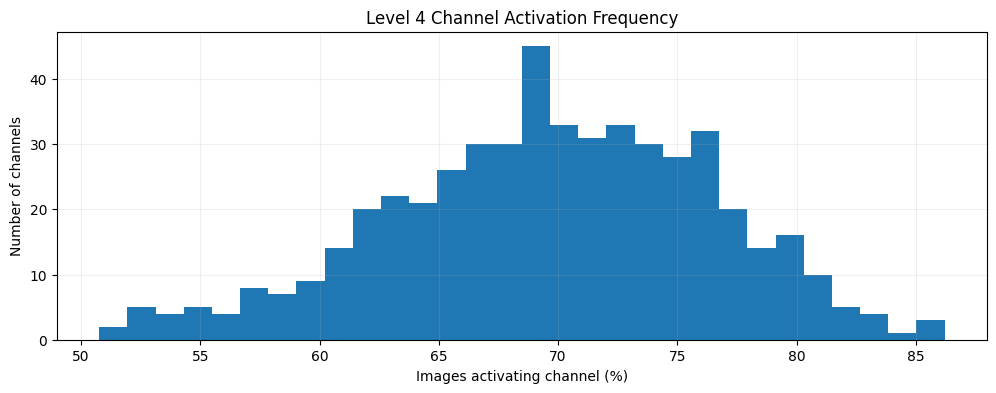

In [14]:

active = (level4_features > 0).any(dim=(2, 3))
frequency = active.float().mean(dim=0).numpy() * 100

channel_activity = pd.DataFrame({
    "channel": np.arange(512),
    "active_image_pct": frequency
})

print(channel_activity.describe())

plt.figure(figsize=(12, 4))
plt.hist(frequency, bins=30)
plt.xlabel("Images activating channel (%)")
plt.ylabel("Number of channels")
plt.title("Level 4 Channel Activation Frequency")
plt.grid(alpha=0.2)
plt.show()


Mean absolute correlation: 0.048191466431742096
Median absolute correlation: 0.03912033124967701
Pairs above 0.90: 0
Pairs above 0.95: 0


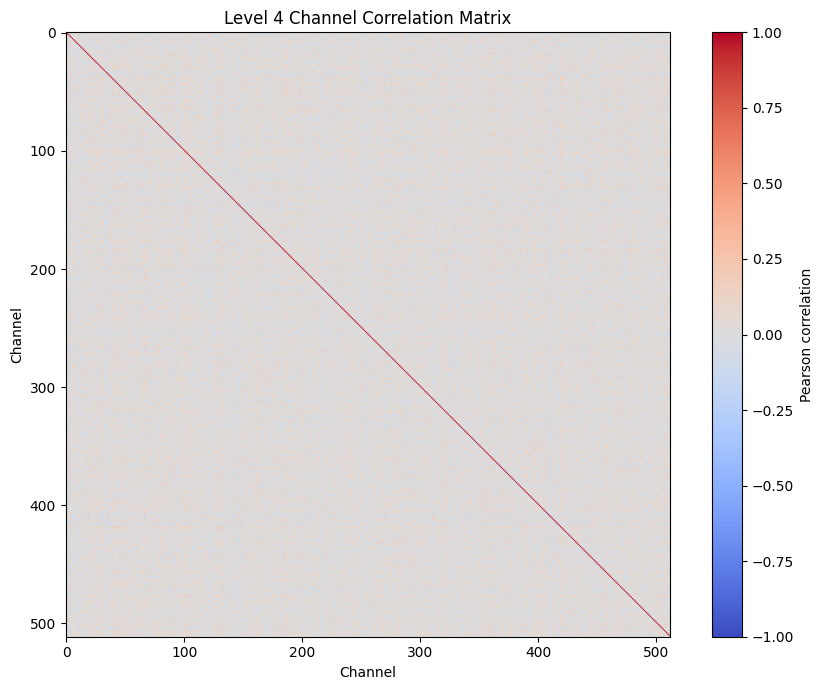

In [15]:

pooled = level4_features.mean(dim=(2, 3)).numpy()
corr = np.corrcoef(pooled, rowvar=False)
corr = np.nan_to_num(corr)

upper = np.abs(corr[np.triu_indices(512, k=1)])

print("Mean absolute correlation:", upper.mean())
print("Median absolute correlation:", np.median(upper))
print("Pairs above 0.90:", (upper > 0.90).sum())
print("Pairs above 0.95:", (upper > 0.95).sum())

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.title("Level 4 Channel Correlation Matrix")
plt.xlabel("Channel")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()


Components for 90% variance: 325
Components for 95% variance: 404
Components for 99% variance: 486


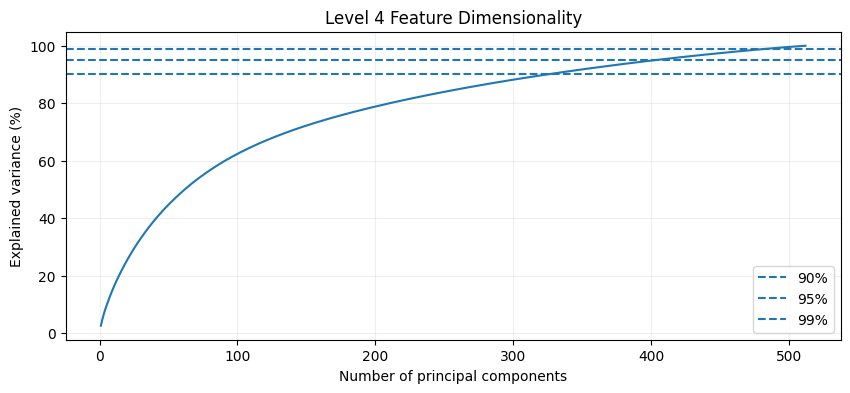

In [16]:

x = pooled - pooled.mean(axis=0, keepdims=True)
singular_values = np.linalg.svd(x, full_matrices=False, compute_uv=False)

variance = singular_values ** 2
variance_ratio = variance / variance.sum()
cumulative = np.cumsum(variance_ratio)

rank_90 = np.searchsorted(cumulative, 0.90) + 1
rank_95 = np.searchsorted(cumulative, 0.95) + 1
rank_99 = np.searchsorted(cumulative, 0.99) + 1

print("Components for 90% variance:", rank_90)
print("Components for 95% variance:", rank_95)
print("Components for 99% variance:", rank_99)

plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, 513), cumulative * 100)
plt.axhline(90, linestyle="--", label="90%")
plt.axhline(95, linestyle="--", label="95%")
plt.axhline(99, linestyle="--", label="99%")
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance (%)")
plt.title("Level 4 Feature Dimensionality")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [18]:

@torch.no_grad()
def evaluate_channel_ablation(model, loader, device, disabled_channels=None):
    model.eval()
    correct, total = 0, 0
    handle = None

    if disabled_channels is not None and len(disabled_channels) > 0:
        channels = torch.as_tensor(disabled_channels, dtype=torch.long, device=device)

        def ablation_hook(module, inputs, output):
            output = output.clone()
            output[:, channels] = 0
            return output

        handle = model.level4[8].register_forward_hook(ablation_hook)

    try:
        for images, labels in tqdm(loader, leave=False):
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    finally:
        if handle is not None:
            handle.remove()

    return 100 * correct / total


baseline = evaluate_channel_ablation(model, val_loader, DEVICE)
rng = np.random.default_rng(42)

results = [{"method": "Baseline", "removed": 0, "accuracy": baseline}]

for fraction in [0.10, 0.20, 0.30]:
    n_remove = round(512 * fraction)

    random_channels = rng.choice(512, size=n_remove, replace=False)
    low_frequency_channels = np.argsort(frequency)[:n_remove]

    for method, channels in [
        ("Random", random_channels),
        ("Low frequency", low_frequency_channels)
    ]:
        accuracy = evaluate_channel_ablation(model, val_loader, DEVICE, channels)
        results.append({
            "method": method,
            "removed": n_remove,
            "accuracy": accuracy
        })

ablation_df = pd.DataFrame(results)
ablation_df["accuracy_drop"] = baseline - ablation_df["accuracy"]
print(ablation_df.to_string(index=False))


  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

       method  removed  accuracy  accuracy_drop
     Baseline        0     66.60           0.00
       Random       51     65.61           0.99
Low frequency       51     65.49           1.11
       Random      102     64.78           1.82
Low frequency      102     63.35           3.25
       Random      154     63.07           3.53
Low frequency      154     61.08           5.52


Analyzing ReLU:   0%|          | 0/157 [00:00<?, ?it/s]


=== LEVEL 4 RELU CHANNEL ACTIVITY ===
images: 10000
total_channels: 512
mean_active_channels: 356.57
median_active_channels: 364.00
min_active_channels: 85
max_active_channels: 473
mean_active_positions: 2117.68
never_active_channels: 0
channels_active_in_all_images: 0


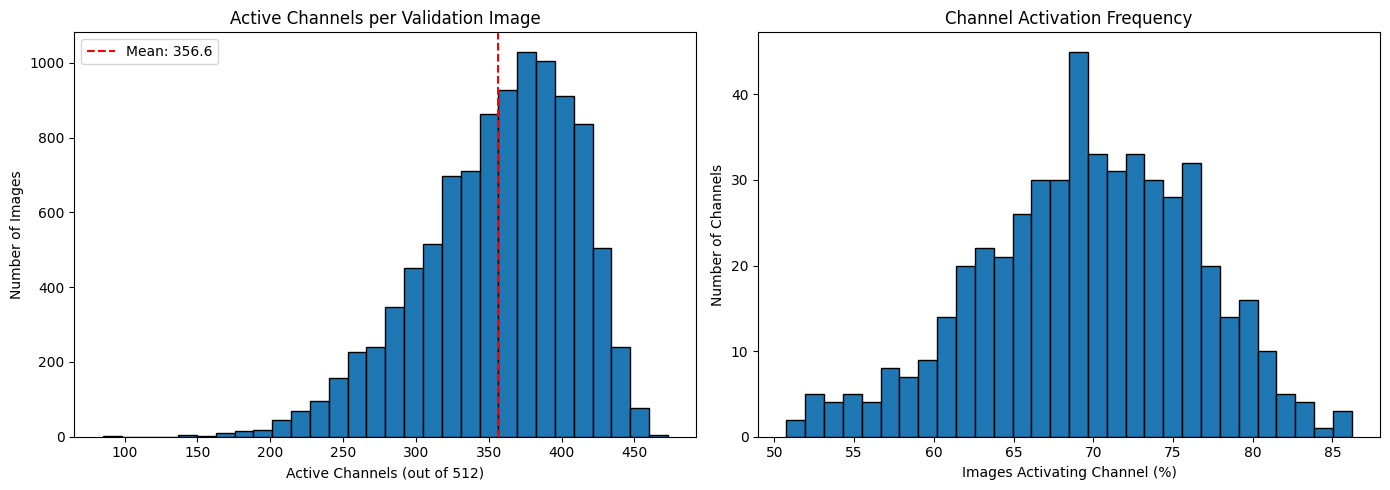

,channel,active_images,active_image_pct
464,464,8621,86.21
217,217,8536,85.36
476,476,8533,85.33
228,228,8389,83.89
434,434,8350,83.50
45,45,8326,83.26
388,388,8315,83.15
443,443,8277,82.77
58,58,8236,82.36
216,216,8226,82.26


,channel,active_images,active_image_pct
442,442,5076,50.76
121,121,5141,51.41
511,511,5231,52.31
345,345,5245,52.45
331,331,5264,52.64
90,90,5264,52.64
52,52,5305,53.05
474,474,5320,53.20
406,406,5331,53.31
310,310,5367,53.67


In [12]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


def analyze_relu_channels(model, val_loader, device, layer_name="level4.8"):
    model.eval()
    target_layer = dict(model.named_modules())[layer_name]

    channel_counts = []
    position_counts = []
    channel_usage = None
    total_images = 0

    def hook_fn(module, inputs, output):
        nonlocal channel_usage, total_images

        x = output.detach()
        active = x > 0

        # [B, C, H, W] -> [B, C]
        active_channels = active.flatten(2).any(dim=2)

        # Active channels per image
        channel_counts.extend(active_channels.sum(dim=1).cpu().tolist())

        # Active spatial positions per image
        position_counts.extend(active.flatten(1).sum(dim=1).cpu().tolist())

        # Number of images activating each channel
        usage = active_channels.sum(dim=0).cpu().numpy()
        channel_usage = usage if channel_usage is None else channel_usage + usage

        total_images += x.shape[0]

    handle = target_layer.register_forward_hook(hook_fn)

    try:
        with torch.inference_mode():
            for images, labels in tqdm(val_loader, desc="Analyzing ReLU"):
                images = images.to(device)
                model(images)
    finally:
        handle.remove()

    channel_counts = np.array(channel_counts)
    position_counts = np.array(position_counts)
    channel_usage = np.array(channel_usage)

    results = {
        "images": total_images,
        "total_channels": len(channel_usage),
        "mean_active_channels": channel_counts.mean(),
        "median_active_channels": np.median(channel_counts),
        "min_active_channels": channel_counts.min(),
        "max_active_channels": channel_counts.max(),
        "mean_active_positions": position_counts.mean(),
        "never_active_channels": int((channel_usage == 0).sum()),
        "channels_active_in_all_images": int((channel_usage == total_images).sum())
    }

    print("\n=== LEVEL 4 RELU CHANNEL ACTIVITY ===")
    for key, value in results.items():
        print(f"{key}: {value:.2f}" if isinstance(value, (float, np.floating)) else f"{key}: {value}")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].hist(channel_counts, bins=30, edgecolor="black")
    axes[0].axvline(channel_counts.mean(), linestyle="--", color="red", label=f"Mean: {channel_counts.mean():.1f}")
    axes[0].set_title("Active Channels per Validation Image")
    axes[0].set_xlabel("Active Channels (out of 512)")
    axes[0].set_ylabel("Number of Images")
    axes[0].legend()

    axes[1].hist(channel_usage / total_images * 100, bins=30, edgecolor="black")
    axes[1].set_title("Channel Activation Frequency")
    axes[1].set_xlabel("Images Activating Channel (%)")
    axes[1].set_ylabel("Number of Channels")

    plt.tight_layout()
    plt.show()

    channel_df = pd.DataFrame({
        "channel": np.arange(len(channel_usage)),
        "active_images": channel_usage,
        "active_image_pct": channel_usage / total_images * 100
    })

    return results, channel_df


results, channel_df = analyze_relu_channels(model, val_loader, DEVICE, layer_name="level4.8")

display(channel_df.sort_values("active_image_pct", ascending=False).head(20))
display(channel_df.sort_values("active_image_pct", ascending=True).head(20))